## **Bagian 1: Setup dan Pemuatan Fitur**

In [ ]:
# ============================================================
# SEL 3.1: Setup Environment
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LinearRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report)
import lightgbm as lgb
from scipy.stats import chi2
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

BASE = '/content/drive/MyDrive/tugas_akhir'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Mounted at /content/drive
Device: cuda


In [ ]:
# ============================================================
# SEL 3.2: Pemuatan dan Verifikasi Fitur per Fold
# ============================================================
def load_fold(fold):
    dd = f'{BASE}/data/features/deep/fold_{fold}'
    hh = f'{BASE}/data/features/handcrafted/fold_{fold}'
    return {
        'X_tr_deep': np.load(f'{dd}/train_deep.npy'),
        'X_val_deep': np.load(f'{dd}/val_deep.npy'),
        'X_te_deep': np.load(f'{dd}/test_deep.npy'),
        'X_tr_hand': np.load(f'{hh}/train_hand.npy'),
        'X_val_hand': np.load(f'{hh}/val_hand.npy'),
        'X_te_hand': np.load(f'{hh}/test_hand.npy'),
        'y_tr': np.load(f'{dd}/train_labels.npy'),
        'y_val': np.load(f'{dd}/val_labels.npy'),
        'y_te': np.load(f'{dd}/test_labels.npy'),
    }

data = {fold: load_fold(fold) for fold in range(1, 6)}

# Verifikasi integritas dimensi
for fold in range(1, 6):
    D = data[fold]
    assert D['X_tr_deep'].shape == (2809, 768), f"Fold {fold}: deep train salah"
    assert D['X_tr_hand'].shape == (2809, 40), f"Fold {fold}: hand train salah"
    assert D['X_te_deep'].shape == (878, 768), f"Fold {fold}: deep test salah"
    print(f"Fold {fold}: Train={D['X_tr_deep'].shape[0]}, "
          f"Val={D['X_val_deep'].shape[0]}, Test={D['X_te_deep'].shape[0]} [OK]")

print("\nSeluruh fitur berhasil dimuat dan terverifikasi.")

Fold 1: Train=2809, Val=703, Test=878 [OK]
Fold 2: Train=2809, Val=703, Test=878 [OK]
Fold 3: Train=2809, Val=703, Test=878 [OK]
Fold 4: Train=2809, Val=703, Test=878 [OK]
Fold 5: Train=2809, Val=703, Test=878 [OK]

Seluruh fitur berhasil dimuat dan terverifikasi.


## **Bagian 2: Complementary Learning Analysis (CLA)**

In [ ]:
# ============================================================
# SEL 3.3 (PERBAIKAN): CLA dengan Agregasi per Fitur
# ============================================================
def run_cla(D):
    """
    Untuk setiap fitur handcrafted ke-i:
    - R² train/test: seberapa baik deep embeddings menjelaskan fitur tersebut.
    - c_max: korelasi Pearson maksimum fitur terhadap seluruh dimensi deep embeddings.
    R² rendah/negatif dan c_max rendah => KOMPLEMENTER.
    """
    results = []

    # Matriks korelasi silang (40 handcrafted x 768 deep) pada data test
    Z_te = np.hstack([D['X_te_hand'], D['X_te_deep']])
    C_te = np.corrcoef(Z_te, rowvar=False)[:40, 40:]
    C_te = np.nan_to_num(C_te)
    cmax_te = np.max(np.abs(C_te), axis=1)

    for i in range(40):
        reg = LinearRegression()
        reg.fit(D['X_tr_deep'], D['X_tr_hand'][:, i])
        r2_tr = reg.score(D['X_tr_deep'], D['X_tr_hand'][:, i])
        r2_te = reg.score(D['X_te_deep'], D['X_te_hand'][:, i])
        results.append({'feature_idx': i, 'r2_tr': r2_tr,
                        'r2_te': r2_te, 'c_max': cmax_te[i]})
    return pd.DataFrame(results)

cla_per_fold = {fold: run_cla(data[fold]) for fold in range(1, 6)}

# --- PERBAIKAN: agregasi per fitur (bukan per fold) ---
cla_all = pd.concat(
    [cla_per_fold[f].assign(fold=f) for f in range(1, 6)],
    ignore_index=True
)

cla_summary = cla_all.groupby('feature_idx').agg(
    r2_tr_mean=('r2_tr', 'mean'),
    r2_tr_std=('r2_tr', 'std'),
    r2_te_mean=('r2_te', 'mean'),
    r2_te_std=('r2_te', 'std'),
    cmax_mean=('c_max', 'mean'),
    cmax_std=('c_max', 'std'),
).reset_index()

# Lampirkan nama fitur dari Notebook 1
fn_path = f'{BASE}/data/features/handcrafted/feature_names.pkl'
if os.path.exists(fn_path):
    with open(fn_path, 'rb') as f:
        FEATURE_NAMES = pickle.load(f)
else:
    FEATURE_NAMES = [f'feat_{i}' for i in range(40)]

cla_summary['feature'] = FEATURE_NAMES

cla_summary.to_csv(f'{BASE}/results/tables/cla_results.csv', index=False)

print("=== RINGKASAN CLA (mean ± std antar 5 fold) ===")
print(cla_summary[['feature', 'r2_te_mean', 'cmax_mean']].round(4).to_string(index=False))
print(f"\nRata-rata c_max keseluruhan: {cla_summary['cmax_mean'].mean():.4f}")
n_comp = int(((cla_summary['r2_te_mean'] < 0.3) & (cla_summary['cmax_mean'] < 0.5)).sum())
print(f"Jumlah fitur komplementer (r2_te < 0.3 dan c_max < 0.5): {n_comp} dari 40")

=== RINGKASAN CLA (mean ± std antar 5 fold) ===
    feature  r2_te_mean  cmax_mean
     L_mean      0.8402     0.4120
      L_std      0.5984     0.4101
     L_skew      0.4662     0.3492
     L_kurt      0.1895     0.2371
     a_mean      0.8609     0.5128
      a_std      0.8938     0.4666
     a_skew      0.5950     0.4077
     a_kurt      0.2481     0.2168
     b_mean      0.8493     0.4537
      b_std      0.8546     0.6558
     b_skew      0.5568     0.4977
     b_kurt      0.2712     0.3476
    cvr_a_b      0.6118     0.4302
      lbp_0      0.5287     0.3658
      lbp_1      0.5406     0.3166
      lbp_2      0.7123     0.4647
      lbp_3      0.8078     0.5054
      lbp_4      0.8360     0.5273
      lbp_5      0.7758     0.4951
      lbp_6      0.8281     0.5188
      lbp_7      0.3084     0.3388
      lbp_8      0.7998     0.5073
      lbp_9      0.5780     0.2999
 hue_hist_0      0.5997     0.4130
 hue_hist_1      0.6542     0.3659
 hue_hist_2      0.4303     0.2486
 hue_hi

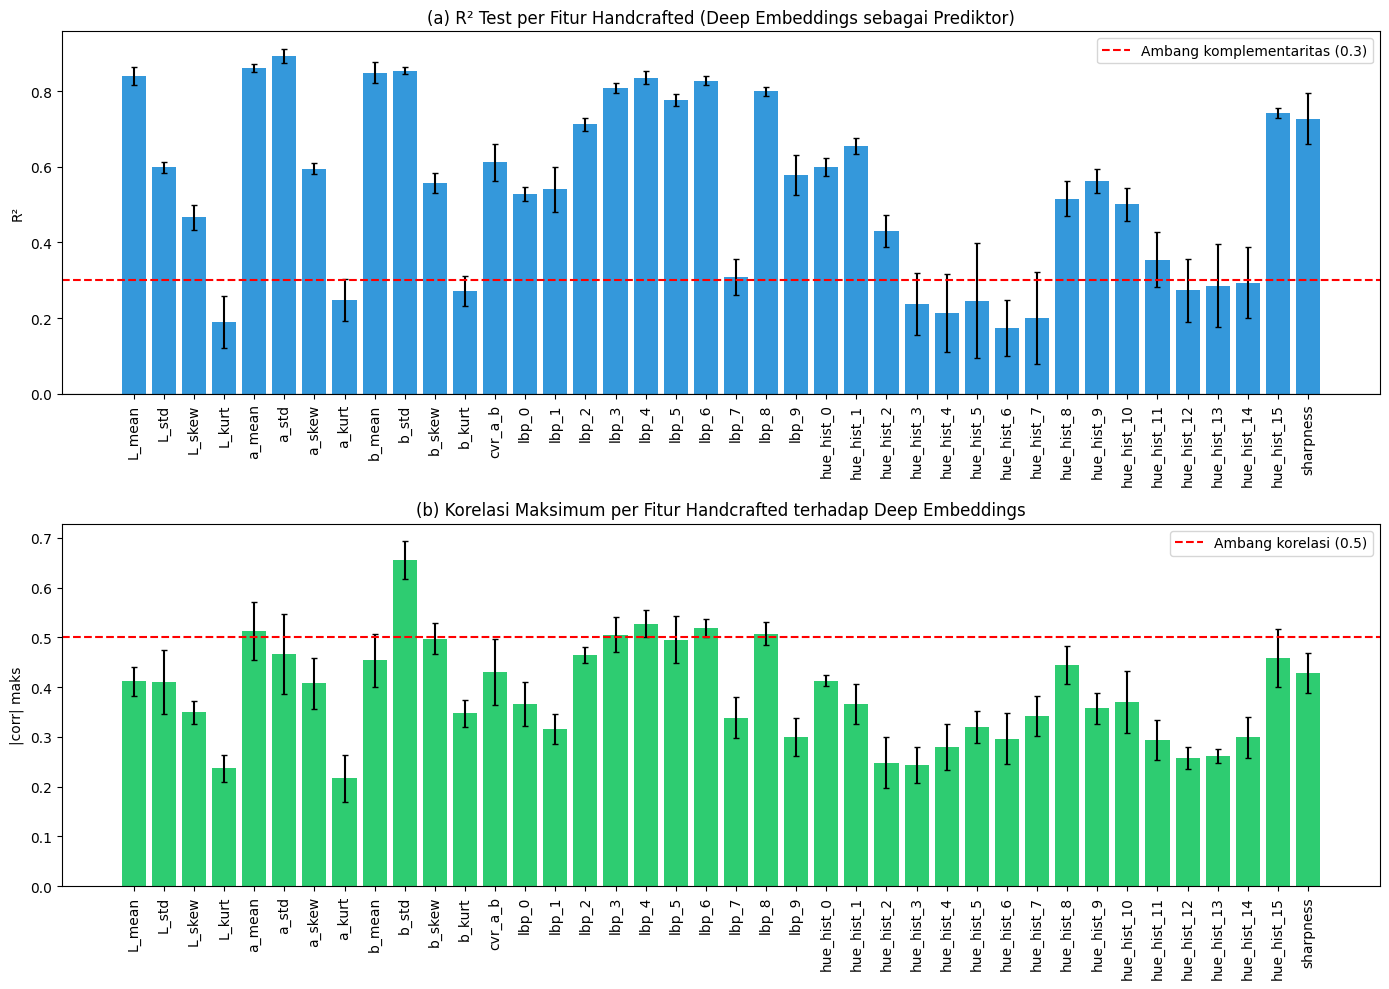

Visualisasi CLA disimpan.


In [ ]:
# ============================================================
# SEL 3.4: Visualisasi CLA
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].bar(cla_summary['feature'], cla_summary['r2_te_mean'],
            yerr=cla_summary['r2_te_std'], color='#3498db', capsize=2)
axes[0].axhline(0.3, color='red', linestyle='--', label='Ambang komplementaritas (0.3)')
axes[0].axhline(0.0, color='black', linestyle='-', linewidth=0.8)
axes[0].set_title('(a) R² Test per Fitur Handcrafted (Deep Embeddings sebagai Prediktor)')
axes[0].set_ylabel('R²')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar(cla_summary['feature'], cla_summary['cmax_mean'],
            yerr=cla_summary['cmax_std'], color='#2ecc71', capsize=2)
axes[1].axhline(0.5, color='red', linestyle='--', label='Ambang korelasi (0.5)')
axes[1].set_title('(b) Korelasi Maksimum per Fitur Handcrafted terhadap Deep Embeddings')
axes[1].set_ylabel('|corr| maks')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.savefig(f'{BASE}/results/figures/cla/cla_summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("Visualisasi CLA disimpan.")

## **Bagian 3: Definisi Model untuk Ablation Study**

In [ ]:
# ============================================================
# SEL 3.5: Arsitektur Konfigurasi A' (Deep Only) dan C (Fusi)
# ============================================================
class DeepOnlyNet(nn.Module):
    """Konfigurasi A': fitur deep (768) -> FCN -> 3 kelas."""
    def __init__(self, deep_dim=768, num_classes=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(deep_dim, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, xd):
        return self.net(xd)

class FusionNet(nn.Module):
    """Konfigurasi C (OURS): fusi deep (768->256) + handcrafted (40->64) -> FCN."""
    def __init__(self, deep_dim=768, hand_dim=40, num_classes=3):
        super().__init__()
        self.deep_proj = nn.Sequential(nn.Linear(deep_dim, 256), nn.BatchNorm1d(256), nn.ReLU())
        self.hand_proj = nn.Sequential(nn.Linear(hand_dim, 64), nn.BatchNorm1d(64), nn.ReLU())
        self.fusion = nn.Sequential(
            nn.Linear(320, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, xd, xh):
        d = self.deep_proj(xd)
        h = self.hand_proj(xh)
        return self.fusion(torch.cat([d, h], dim=1))

print("Arsitektur A' dan C berhasil didefinisikan.")

Arsitektur A' dan C berhasil didefinisikan.


In [ ]:
# ============================================================
# SEL 3.6: Fungsi Training Generik dengan Early Stopping
# ============================================================
import copy

def make_loader(Xd, Xh, y, batch, shuffle):
    tensors = [torch.tensor(Xd, dtype=torch.float32)]
    if Xh is not None:
        tensors.append(torch.tensor(Xh, dtype=torch.float32))
    tensors.append(torch.tensor(y, dtype=torch.long))
    return DataLoader(TensorDataset(*tensors), batch_size=batch, shuffle=shuffle)

def fit_net(net, is_fusion, D, epochs=100, patience=10, batch=64, lr=1e-3):
    torch.manual_seed(42)
    net.to(device)

    # Class weights dari data training fold ini
    cw = compute_class_weight('balanced', classes=np.array([0, 1, 2]), y=D['y_tr'])
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(cw, dtype=torch.float32).to(device))

    optimizer = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)

    tr_loader = make_loader(D['X_tr_deep'],
                            D['X_tr_hand'] if is_fusion else None,
                            D['y_tr'], batch, shuffle=True)
    val_loader = make_loader(D['X_val_deep'],
                             D['X_val_hand'] if is_fusion else None,
                             D['y_val'], batch, shuffle=False)
    te_loader = make_loader(D['X_te_deep'],
                            D['X_te_hand'] if is_fusion else None,
                            D['y_te'], batch, shuffle=False)

    best_val_loss = float('inf')
    best_state = copy.deepcopy(net.state_dict())
    wait = 0

    for epoch in range(epochs):
        net.train()
        for batch_data in tr_loader:
            if is_fusion:
                xd, xh, y = batch_data
                xd, xh, y = xd.to(device), xh.to(device), y.to(device)
            else:
                xd, y = batch_data
                xd, y = xd.to(device), y.to(device)
            optimizer.zero_grad()
            out = net(xd, xh) if is_fusion else net(xd)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

        net.eval()
        val_loss, preds, trues = 0.0, [], []
        with torch.no_grad():
            for batch_data in val_loader:
                if is_fusion:
                    xd, xh, y = batch_data
                    xd, xh, y = xd.to(device), xh.to(device), y.to(device)
                    out = net(xd, xh)
                else:
                    xd, y = batch_data
                    xd, y = xd.to(device), y.to(device)
                    out = net(xd)
                val_loss += criterion(out, y).item() * y.size(0)
                preds += out.argmax(1).cpu().tolist()
                trues += y.cpu().tolist()
        val_loss /= len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(net.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    # Evaluasi test dengan bobot terbaik
    net.load_state_dict(best_state)
    net.eval()
    test_preds, test_trues = [], []
    with torch.no_grad():
        for batch_data in te_loader:
            if is_fusion:
                xd, xh, y = batch_data
                xd, xh = xd.to(device), xh.to(device)
                out = net(xd, xh)
            else:
                xd, y = batch_data
                xd = xd.to(device)
                out = net(xd)
            test_preds += out.argmax(1).cpu().tolist()
            test_trues += y.cpu().tolist()
    return np.array(test_preds), np.array(test_trues)

print("Fungsi training siap.")

Fungsi training siap.


## **Bagian 4: Eksekusi Ablation Study (3 Konfigurasi × 5 Fold)**

In [ ]:
# ============================================================
# SEL 3.7: Konfigurasi A' (Deep Only), B (Handcrafted+LGBM), C (Fusi)
# ============================================================
results_ablation = []
pooled = {cfg: {'y_true': [], 'y_pred': []}
          for cfg in ['A_prime', 'B_hand', 'C_fused']}

for fold in range(1, 6):
    print(f"\n{'='*20} FOLD {fold} {'='*20}")
    D = data[fold]

    # --- Konfigurasi A': Deep Only + FCN ---
    preds_a, true_a = fit_net(DeepOnlyNet(), is_fusion=False, D=D)
    pooled['A_prime']['y_true'].append(true_a)
    pooled['A_prime']['y_pred'].append(preds_a)

    # --- Konfigurasi B: Handcrafted + LGBM (hyperparameter dari Hoang et al. 2026a) ---
    lgbm = lgb.LGBMClassifier(boosting_type='dart', class_weight='balanced',
                              n_estimators=300, max_depth=50, num_leaves=35,
                              random_state=42, verbose=-1)
    lgbm.fit(D['X_tr_hand'], D['y_tr'])
    preds_b = lgbm.predict(D['X_te_hand'])
    pooled['B_hand']['y_true'].append(D['y_te'])
    pooled['B_hand']['y_pred'].append(preds_b)

    # --- Konfigurasi C (OURS): Fusi Deep + Handcrafted ---
    preds_c, true_c = fit_net(FusionNet(), is_fusion=True, D=D)
    pooled['C_fused']['y_true'].append(true_c)
    pooled['C_fused']['y_pred'].append(preds_c)

    # Catat metrik per fold
    for cfg, yp, yt in [('A_prime', preds_a, true_a),
                        ('B_hand', preds_b, D['y_te']),
                        ('C_fused', preds_c, true_c)]:
        results_ablation.append({
            'fold': fold, 'config': cfg,
            'accuracy': accuracy_score(yt, yp),
            'macro_f1': f1_score(yt, yp, average='macro'),
            'mcc': matthews_corrcoef(yt, yp),
        })
    print(f"  Fold {fold} selesai: A'={results_ablation[-3]['accuracy']:.4f} | "
          f"B={results_ablation[-2]['accuracy']:.4f} | C={results_ablation[-1]['accuracy']:.4f}")

df_ablation = pd.DataFrame(results_ablation)
df_ablation.to_csv(f'{BASE}/results/tables/ablation_results.csv', index=False)
print("\nAblation study selesai. Hasil per fold disimpan.")


==================== FOLD 1 ====================
  Fold 1 selesai: A'=0.7756 | B=0.6731 | C=0.7813

==================== FOLD 2 ====================
  Fold 2 selesai: A'=0.7790 | B=0.6765 | C=0.7870

==================== FOLD 3 ====================
  Fold 3 selesai: A'=0.7995 | B=0.6708 | C=0.7938

==================== FOLD 4 ====================
  Fold 4 selesai: A'=0.7756 | B=0.6788 | C=0.7813

==================== FOLD 5 ====================
  Fold 5 selesai: A'=0.8121 | B=0.6674 | C=0.8132

Ablation study selesai. Hasil per fold disimpan.


## **Bagian 5: Agregasi Hasil, Uji Signifikansi, dan Visualisasi**

In [ ]:
# ============================================================
# SEL 3.8: Ringkasan Mean ± Std dan Uji McNemar (A' vs C)
# ============================================================
summary = df_ablation.groupby('config')[['accuracy', 'macro_f1', 'mcc']].agg(
    ['mean', 'std']).round(4)
print("=== RINGKASAN ABLATION (mean ± std, 5 fold) ===")
print(summary.to_string())

summary.to_csv(f'{BASE}/results/tables/cv_results_summary.csv')

# Uji McNemar pada prediksi pooled (4.390 sampel test)
def mcnemar_test(y_true, p1, p2):
    c1 = (p1 == y_true)
    c2 = (p2 == y_true)
    b = np.sum(c1 & ~c2)   # A' benar, C salah
    c = np.sum(~c1 & c2)   # A' salah, C benar
    if (b + c) == 0:
        return 0.0, 1.0
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    p_val = chi2.sf(stat, df=1)
    return stat, p_val, b, c

yt_all = np.concatenate(pooled['A_prime']['y_true'])
pa_all = np.concatenate(pooled['A_prime']['y_pred'])
pc_all = np.concatenate(pooled['C_fused']['y_pred'])
stat, p_val, b, c = mcnemar_test(yt_all, pa_all, pc_all)

print(f"\n=== UJI McNEMAR: Konfigurasi C vs A' ===")
print(f"Diskordan (C benar, A' salah): {c} | (A' benar, C salah): {b}")
print(f"Statistik McNemar: {stat:.4f} | p-value: {p_val:.4f}")
print(f"Signifikan (alpha=0.05): {'YA' if p_val < 0.05 else 'TIDAK'}")

=== RINGKASAN ABLATION (mean ± std, 5 fold) ===
        accuracy         macro_f1             mcc        
            mean     std     mean     std    mean     std
config                                                   
A_prime   0.7884  0.0166   0.7833  0.0163  0.6832  0.0262
B_hand    0.6733  0.0045   0.6610  0.0057  0.5031  0.0071
C_fused   0.7913  0.0133   0.7852  0.0128  0.6876  0.0205

=== UJI McNEMAR: Konfigurasi C vs A' ===
Diskordan (C benar, A' salah): 75 | (A' benar, C salah): 62
Statistik McNemar: 1.0511 | p-value: 0.3053
Signifikan (alpha=0.05): TIDAK


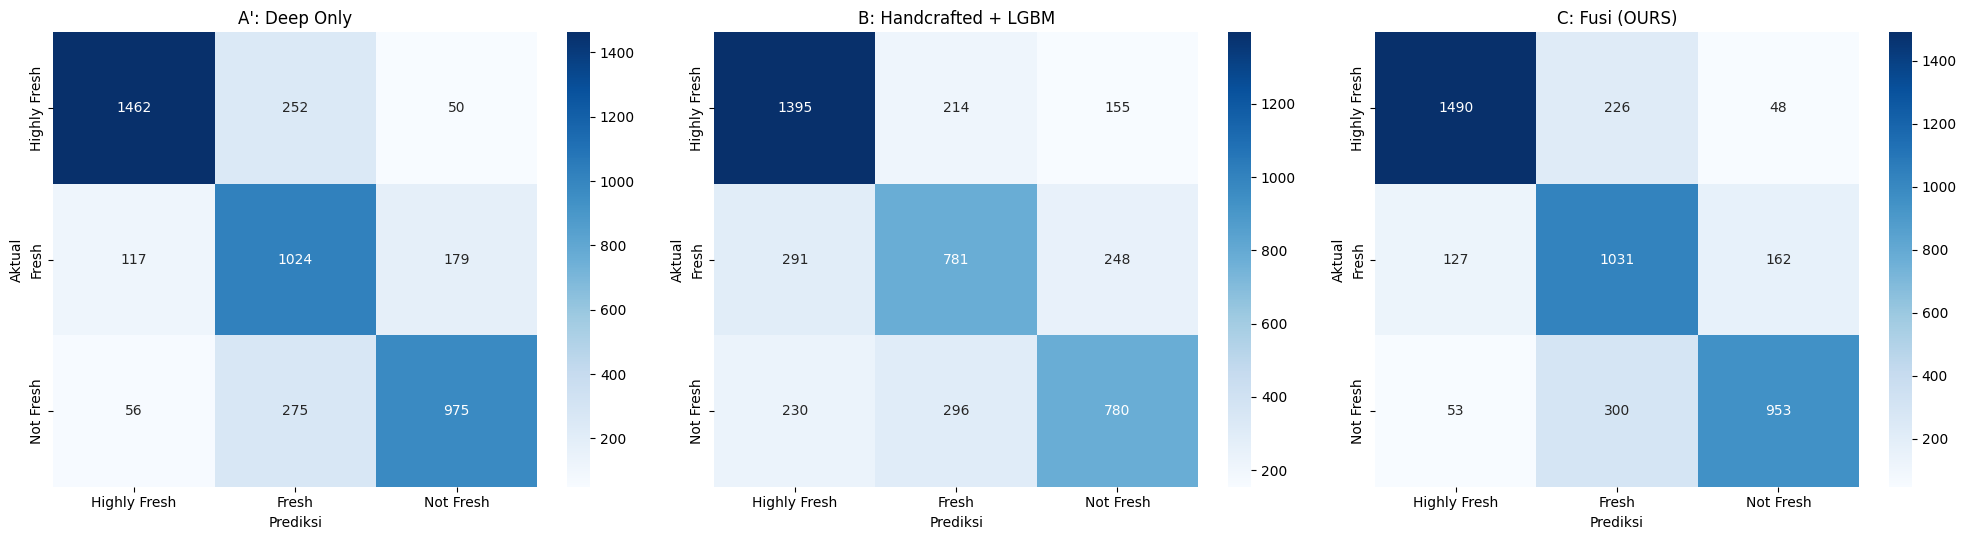

=== METRIK PER KELAS — KONFIGURASI C (FUSI) ===
              precision  recall  f1-score    support
Highly Fresh     0.8922  0.8447    0.8678  1764.0000
Fresh            0.6622  0.7811    0.7167  1320.0000
Not Fresh        0.8194  0.7297    0.7720  1306.0000
accuracy         0.7913  0.7913    0.7913     0.7913
macro avg        0.7913  0.7851    0.7855  4390.0000
weighted avg     0.8014  0.7913    0.7939  4390.0000


In [ ]:
# ============================================================
# SEL 3.9: Confusion Matrix dan Metrik per Kelas (Konfigurasi C)
# ============================================================
cm_c = confusion_matrix(yt_all, pc_all)
cm_a = confusion_matrix(yt_all, pa_all)
yb_all = np.concatenate(pooled['B_hand']['y_true'])
pb_all = np.concatenate(pooled['B_hand']['y_pred'])
cm_b = confusion_matrix(yb_all, pb_all)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
labels = ['Highly Fresh', 'Fresh', 'Not Fresh']
for ax, cm, title in [(axes[0], cm_a, "A': Deep Only"),
                      (axes[1], cm_b, 'B: Handcrafted + LGBM'),
                      (axes[2], cm_c, 'C: Fusi (OURS)')]:
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(title)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig(f'{BASE}/results/figures/confusion_matrices/cm_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Metrik per kelas untuk Konfigurasi C
report_c = classification_report(yt_all, pc_all,
                                 target_names=labels, output_dict=True)
df_perclass = pd.DataFrame(report_c).transpose().round(4)
df_perclass.to_csv(f'{BASE}/results/tables/per_class_metrics.csv')
print("=== METRIK PER KELAS — KONFIGURASI C (FUSI) ===")
print(df_perclass.to_string())

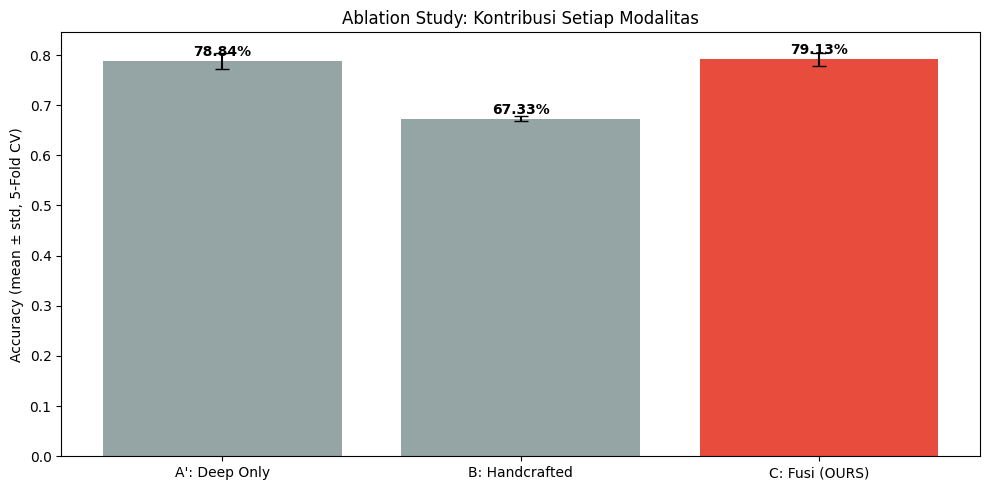

                  Studi                                  Metode  Accuracy (%)    Protokol Evaluasi
 Prasetyo et al. (2022)                        MB-BE (24 kelas)     60.020000         Single split
Rakhmat & Haekal (2023)            MobileNetV3-Small (24 kelas)     68.000000         Single split
   Yildiz et al. (2024)                   VGG19 + ANN (3 kelas)     77.300000 10-fold CV (leakage)
   Hoang et al. (2026a)       Handcrafted FS17 + LGBM (3 kelas)     77.190000             Hold-out
    Madhu et al. (2026)         FCLN ResNet50 + expert features     81.030000         Single split
     Zare et al. (2026)           Inception-v3 + SVM (24 kelas)     81.210000         Single split
   Hoang et al. (2026b)      Swin-Tiny + RF + LGBM FS (3 kelas)     85.990000         Single split
              OURS (A')           Swin-Tiny deep features + FCN     78.838269            5-Fold CV
               OURS (C) Fusi Swin-Tiny + handcrafted (40 fitur)     79.134396            5-Fold CV

NOTEBOOK 

In [ ]:
# ============================================================
# SEL 3.10: Bar Chart Ablation dan Perbandingan Literatur
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))
means = df_ablation.groupby('config')['accuracy'].mean()
stds = df_ablation.groupby('config')['accuracy'].std()
colors = ['#95a5a6', '#95a5a6', '#e74c3c']
ax.bar(['A\': Deep Only', 'B: Handcrafted', 'C: Fusi (OURS)'],
       means.values, yerr=stds.values, capsize=5, color=colors)
ax.set_ylabel('Accuracy (mean ± std, 5-Fold CV)')
ax.set_title('Ablation Study: Kontribusi Setiap Modalitas')
for i, v in enumerate(means.values):
    ax.text(i, v + 0.01, f"{v*100:.2f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{BASE}/results/figures/ablation/ablation_bar_chart.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Tabel perbandingan literatur
lit = pd.DataFrame([
    ['Prasetyo et al. (2022)', 'MB-BE (24 kelas)', 60.02, 'Single split'],
    ['Rakhmat & Haekal (2023)', 'MobileNetV3-Small (24 kelas)', 68.00, 'Single split'],
    ['Yildiz et al. (2024)', 'VGG19 + ANN (3 kelas)', 77.30, '10-fold CV (leakage)'],
    ['Hoang et al. (2026a)', 'Handcrafted FS17 + LGBM (3 kelas)', 77.19, 'Hold-out'],
    ['Madhu et al. (2026)', 'FCLN ResNet50 + expert features', 81.03, 'Single split'],
    ['Zare et al. (2026)', 'Inception-v3 + SVM (24 kelas)', 81.21, 'Single split'],
    ['Hoang et al. (2026b)', 'Swin-Tiny + RF + LGBM FS (3 kelas)', 85.99, 'Single split'],
    ['OURS (A\')', 'Swin-Tiny deep features + FCN', means['A_prime']*100, '5-Fold CV'],
    ['OURS (C)', 'Fusi Swin-Tiny + handcrafted (40 fitur)', means['C_fused']*100, '5-Fold CV'],
], columns=['Studi', 'Metode', 'Accuracy (%)', 'Protokol Evaluasi'])
lit.to_csv(f'{BASE}/results/tables/comparison_with_literature.csv', index=False)
print(lit.to_string(index=False))

print("\n" + "="*60)
print("NOTEBOOK 3 SELESAI.")
print("="*60)

## **Tambahan**

In [ ]:
# ============================================================
# SEL 3.11 (OPSIONAL): Fusi Terpandu CLA (CLA-Guided Selection)
# ============================================================
sel_mask = (cla_summary['r2_te_mean'] < 0.3) & (cla_summary['cmax_mean'] < 0.5)
sel_idx = np.where(sel_mask.values)[0]
print(f"Fitur terpilih ({len(sel_idx)}):",
      cla_summary.loc[sel_mask, 'feature'].tolist())

results_sel, pooled_sel = [], {'y_true': [], 'y_pred': []}

for fold in range(1, 6):
    D = data[fold]
    D_sel = dict(D)
    D_sel['X_tr_hand'] = D['X_tr_hand'][:, sel_idx]
    D_sel['X_val_hand'] = D['X_val_hand'][:, sel_idx]
    D_sel['X_te_hand'] = D['X_te_hand'][:, sel_idx]

    preds, trues = fit_net(FusionNet(hand_dim=len(sel_idx)),
                           is_fusion=True, D=D_sel)
    pooled_sel['y_true'].append(trues)
    pooled_sel['y_pred'].append(preds)
    results_sel.append({'config': 'C_sel', 'fold': fold,
                        'accuracy': accuracy_score(trues, preds),
                        'macro_f1': f1_score(trues, preds, average='macro'),
                        'mcc': matthews_corrcoef(trues, preds)})
    print(f"  Fold {fold}: C_sel={results_sel[-1]['accuracy']:.4f}")

df_sel = pd.DataFrame(results_sel)
print(f"\nC_sel ({len(sel_idx)} fitur komplementer): "
      f"{df_sel['accuracy'].mean()*100:.2f}% ± {df_sel['accuracy'].std()*100:.2f}%")

yt_all = np.concatenate(pooled_sel['y_true'])
ps_all = np.concatenate(pooled_sel['y_pred'])
pa_all = np.concatenate(pooled['A_prime']['y_pred'])
stat2, p2, b2, c2 = mcnemar_test(yt_all, pa_all, ps_all)
print(f"McNemar C_sel vs A': stat={stat2:.4f}, p={p2:.4f} (b={b2}, c={c2})")

Fitur terpilih (11): ['L_kurt', 'a_kurt', 'b_kurt', 'hue_hist_3', 'hue_hist_4', 'hue_hist_5', 'hue_hist_6', 'hue_hist_7', 'hue_hist_12', 'hue_hist_13', 'hue_hist_14']
  Fold 1: C_sel=0.7756
  Fold 2: C_sel=0.7768
  Fold 3: C_sel=0.7984
  Fold 4: C_sel=0.7813
  Fold 5: C_sel=0.8087

C_sel (11 fitur komplementer): 78.82% ± 1.47%
McNemar C_sel vs A': stat=0.0000, p=1.0000 (b=59, c=58)
